# Lab 9

Author: Khanh Do

In [2]:
## Standard Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import math

## Question 1

In [3]:
## Squared Error Cost for Linear Regression
def cost_function(X, y, w):
    n = len(y)
    pred_y = np.dot(X,w)
    err = y - pred_y
    cost = (1./n)*np.dot(np.transpose(err),err)                 
    return cost 

## Simulated Data for Question 1
np.random.seed(0)
x = np.linspace(-10, 10, 100)
y = 3 * x + np.random.normal(0, 3, 100)

### Part A

If a simple linear regression model with a single predictor and no intercept is used then: 
- The dimension of **X** is $n \times 1$
- The dimension of **y** is $n \times 1$
- The dimension of $\hat{w}$ if $1 \times 1$.

### Part B

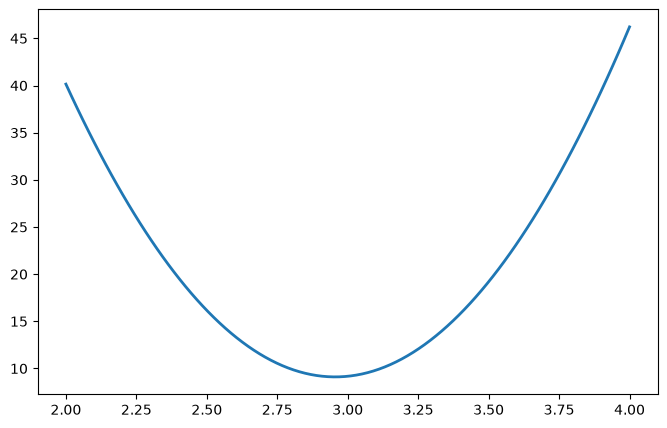

In [4]:
def cost_function_modified(X, y, w):
    n = len(y)
    pred_y = X * w
    err = y - pred_y
    cost = (1./n)*np.dot(np.transpose(err),err)                 
    return cost 

w1s = np.linspace(2, 4, 100)
costs = []
for w1 in w1s:
    costs.append(cost_function_modified(x, y, w1))
    
plt.figure(figsize=(8, 5))
plt.plot(w1s, costs, linewidth=2)

### Part C

The sign of the gradient value should be negative because at $\hat{w_1} = 2$, the tangent line is downward. To improve the cost, we should increase $\hat{w_1}$.

### Part D

The magnitude of the gradient value should be smaller because on the graph, the tangent at $\hat{w_1}=2.7$ is flatter because it is closer to the bottom of the parabola.

### Part E

The irreducible error here would be the random noise added to $3x$. Even if we use the true slope of $3$, we still cannot recover the true observed values due to the noise. Thus it is irreducible. We can see from the graph the bottom of the parabola shows the lowest MSE for that simulated sample.

## Question 2

In [5]:
## Define gradient descent function for linear regression
def grad_descent(X, y, w, alpha, n_iter):
    costs = np.zeros(n_iter)
    n = len(y) 
    
    for i in range(n_iter):
        pred_y = np.dot(X,w)
        grad = (-2./n)*np.dot(np.transpose(X), (y - pred_y))
        w = w - alpha*grad
        costs[i] = cost_function(X, y, w)
        
    return w, costs

### Part A

$z = y - \hat{y}$

$\hat{y} = e^{\hat{w_1}x}$

$\dfrac{d\text{cost}}{d\hat{w_1}} = \dfrac{2}{n} \times -I \times x\hat{y} = \dfrac{-2}{n}z^T\hat{y}x = \dfrac{-2}{n}(y - \hat{y})^T\hat{y}x = \dfrac{-2}{n}(y - e^{\hat{w_1}x})^Te^{\hat{w_1}x}x$

In [6]:
def cost_function_2a(x, y, w):
    n = len(y)
    pred_y = np.exp(w*x)
    err = y - pred_y
    cost = (1./n)*np.dot(np.transpose(err),err)                 
    return cost 

In [7]:
def grad_descent_2a(x, y, w):
    n = len(y)
    pred_y = np.exp(w*x)
    err = y - pred_y
    return (-2./n)*np.dot(np.transpose(err), pred_y * x)
    

### Part B

In [8]:
## Define gradient descent function for linear regression
def grad_descent_modified(X, y, w, alpha, n_iter):
    costs = np.zeros(n_iter)
    n = len(y) 
    
    for i in range(n_iter):
        grad = grad_descent_2a(X, y, w)
        w = w - alpha*grad
        costs[i] = cost_function_2a(X, y, w)
        
    return w, costs

### Part C

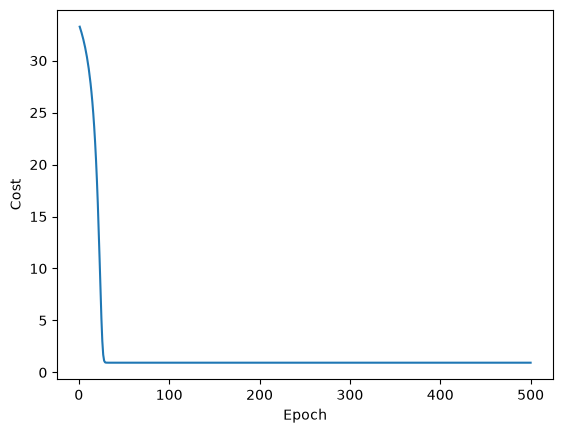

-2.03708742374837


In [9]:
## Simulated Data for Question 2
np.random.seed(0)
x = np.linspace(-1.5, 1.5, 100)
y = np.exp(-2 * x) + np.random.normal(0, 1, 100)

w_hat, gdres = grad_descent_modified(x, y, w=0.0, alpha=0.005, n_iter=500)

epochs = np.arange(1, len(gdres) + 1)
plt.plot(epochs, gdres)
plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.show()

print(w_hat)

### Part D

Comparing with the true value of $-2$, our final estimate of $w_1$ being around $-2.037$ is very close. Since it's such a small difference potentially explained by noise, I would say the gradient descent effectively estimated this parameter.

## Question 3

### Part A

If we increased the number of training epochs, I would not expect our weight estimates to exactly match those found by sklearn because sklearn finds the coefficients that minimize squared error across all homes while our batch approach only uses 5 homes at a time. One batch might push the weights up while the next one push it down. With a fixed learning rate, the weights might just fluctuate around the sklearn estimates.

### Part B

In [14]:
## Define gradient descent function for linear regression
def batch_grad_descent_modified(X, y, w, alpha, n_iter, batch_size):
    costs = np.zeros(n_iter)
    n = len(y) 
    
    for epoch in range(n_iter):
        # Shuffle observations
        idx = np.random.permutation(n)
        X_shuff = X[idx]
        y_shuff = y[idx]
        
        # Process all the mini-batches
        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            
            batch_X = X_shuff[start:end]
            batch_y = y_shuff[start:end]

            grad = grad_descent_2a(batch_X, batch_y, w)
            w = w - alpha * grad
            
        costs[epoch] = cost_function_2a(X, y, w)
        
    return w, costs

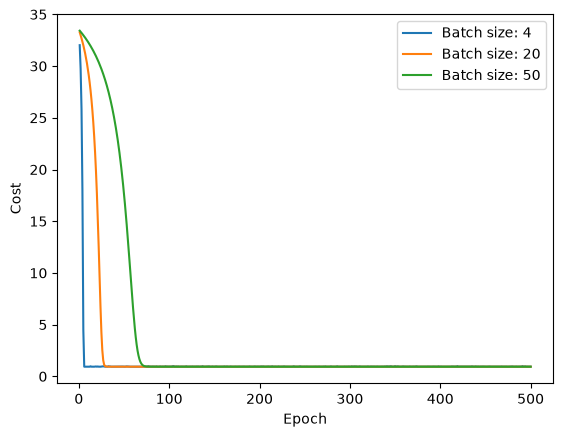

In [17]:
## Simulated Data for Question 2
np.random.seed(0)
x = np.linspace(-1.5, 1.5, 100)
y = np.exp(-2 * x) + np.random.normal(0, 1, 100)

for batch_size in [4, 20, 50]:
    w_hat, costs = batch_grad_descent_modified(x, y, w=0.0, alpha=0.001, n_iter=500, batch_size=batch_size)
    plt.plot(np.arange(1, len(costs) + 1), costs, label=f"Batch size: {batch_size}")

plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.legend()
plt.show()

### Part C

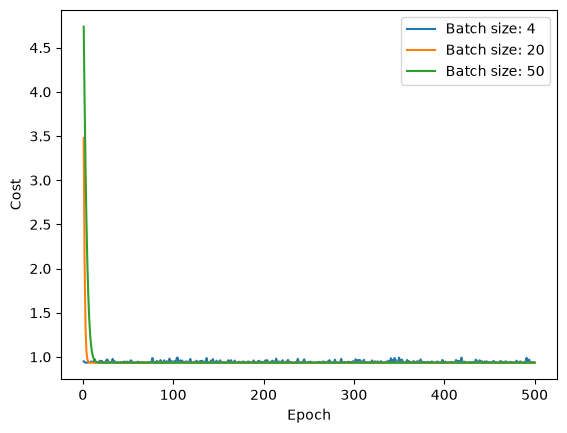

In [18]:
## Simulated Data for Question 2
np.random.seed(0)
x = np.linspace(-1.5, 1.5, 100)
y = np.exp(-2 * x) + np.random.normal(0, 1, 100)

for batch_size in [4, 20, 50]:
    w_hat, costs = batch_grad_descent_modified(x, y, w=-1.7, alpha=0.001, n_iter=500, batch_size=batch_size)
    plt.plot(np.arange(1, len(costs) + 1), costs, label=f"Batch size: {batch_size}")

plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.legend()
plt.show()

We can see from the plot above that there are a lot more spikes on the blue line (batch size: 4) than the other two and green line is the smoothest (batch size: 50). These differences occur because a small batch size, like 4, gives a more variable estimate of the full-dataset gradient vs. a higher batch size, like 50, estimates over more observations, thus have more stable updates. An adventage of a smaller batch size is we can reach a low cost in fewer epochs because the weight gets updated more often per epoch. A disadvantage is like we have seen, not as smooth convergence and may fluctuate more near the minimum.